In [2]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from compcats.models import resnet50_imagenet1kv2, resnet18_imagenet1kv1
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils

import main_analysis as ma
import paths

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
KONKLE_LOCALIZER_DIR = paths.KONKLE_LOCALIZER_DIR

froi = 'FFA'
pref_category = 'faces'
tthreshold = 2
model_localizer = 'grillspector'
subject = 2
subset = 515

plot_dir = f'{PLOTS_DIR}/schematic'
os.makedirs(plot_dir, exist_ok=True)

# Load ResNet50-ImageNet
model = resnet50_imagenet1kv2.get_model()

In [ ]:
# Grill-Spector FBSOWSc
gs_acts = model_utils.get_dataset_activations(
    MODELS_DIR, GRILLSPECTOR_LOCALIZER_DIR, \
    model, ma.get_froi_models_layers(froi, froi)[model.name],
    dataset='localizer', localizer_type=model_localizer, \
    froi=froi, tthreshold=tthreshold, \
    froi_localizer=model_localizer, froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR
)
gs_acts_univariate = {k: v.mean(axis=-1) for k, v in gs_acts.items()}

# Prepare data for plotting with z-scoring
categories = list(gs_acts_univariate.keys())

# Reorder categories and rename 'places' to 'scenes'
category_mapping = {'places': 'scenes', 'scrambledobjects': 'scrambled objects'}
ordered_categories = ['faces', 'bodies', 'places', 'objects', 'characters', 'scrambledobjects']
display_names = [category_mapping.get(cat, cat) for cat in ordered_categories]

# Get all activations and compute overall mean and std for z-scoring
all_vals = torch.cat([gs_acts_univariate[cat] for cat in categories])
overall_mean = all_vals.mean().cpu().numpy()
overall_std = all_vals.std().cpu().numpy()

# Compute z-scored medians and SEMs for the ordered categories
z_medians = [(torch.median(gs_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
z_sems = [(torch.std(gs_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(gs_acts_univariate[cat]))) / overall_std for cat in ordered_categories]

# Set up the plot
plt.figure(figsize=(10, 6))
bar_positions = np.arange(len(ordered_categories))
# bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=3, 
#                color=['coral' if cat == pref_category else 'skyblue' for cat in ordered_categories])
bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=3, color='red')

# Highlight the preferred category
for i, cat in enumerate(ordered_categories):
    if cat == pref_category:
        # bars[i].set_color('coral')
        bars[i].set_color('red')
        bars[i].set_edgecolor('black')
        bars[i].set_linewidth(1)

# Add horizontal line at z=0
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)

# Add labels and title
# Remove top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xlabel('Categories', fontsize=12)
plt.ylabel('Z-scored Unit-averaged Activations', fontsize=12)
# plt.title(f'ResNet50 z-scored Univariate Responses of face-selective units', fontsize=14)
plt.xticks(bar_positions, [cat.capitalize() for cat in display_names], rotation=45)
plt.tight_layout()

plt.savefig(f'{plot_dir}/model_localization_contrast.pdf', dpi=300, bbox_inches='tight')
# plt.show()

100%|██████████| 1/1 [00:00<00:00,  1.48it/s]


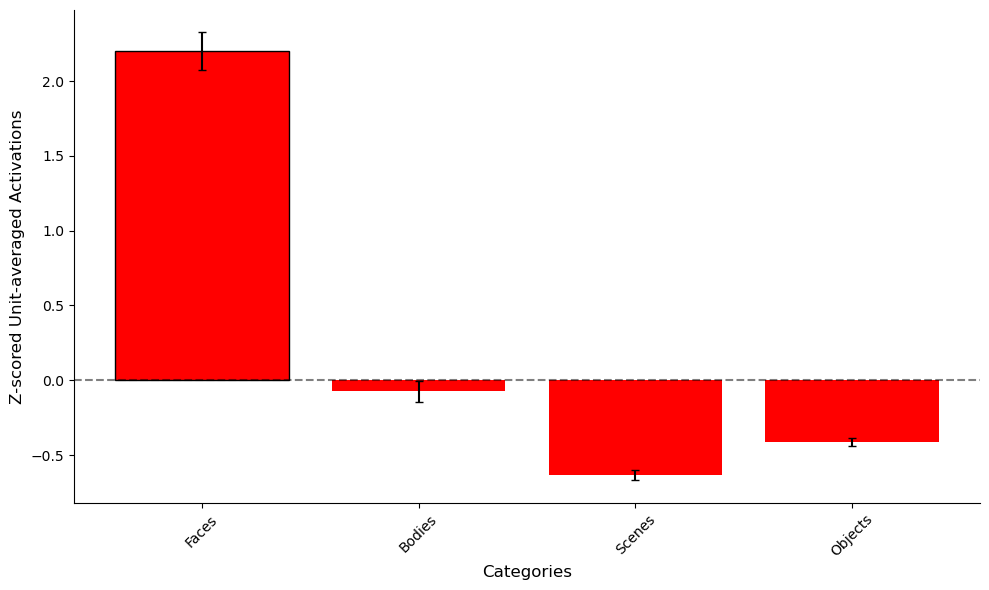

In [8]:
# Konkle FBSO
ko_acts = model_utils.get_dataset_activations(
    MODELS_DIR, KONKLE_LOCALIZER_DIR, \
    model, ma.get_froi_models_layers(froi, froi)[model.name],
    dataset='localizer', localizer_type='konkle', \
    froi=froi, tthreshold=tthreshold, \
    froi_localizer=model_localizer, froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR
)
ko_acts_univariate = {k: v.mean(axis=-1) for k, v in ko_acts.items()}

# Prepare data for plotting with z-scoring
categories = list(ko_acts_univariate.keys())

# Reorder categories and rename 'places' to 'scenes'
# category_mapping = {'places': 'scenes', 'scrambledobjects': 'scrambled objects'}
# ordered_categories = ['faces', 'bodies', 'places', 'objects', 'characters', 'scrambledobjects']
ordered_categories = ['faces', 'bodies', 'scenes', 'objects']
# display_names = [category_mapping.get(cat, cat) for cat in ordered_categories]

# Get all activations and compute overall mean and std for z-scoring
all_vals = torch.cat([ko_acts_univariate[cat] for cat in categories])
overall_mean = all_vals.mean().cpu().numpy()
overall_std = all_vals.std().cpu().numpy()

# Compute z-scored medians and SEMs for the ordered categories
z_medians = [(torch.median(ko_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
z_sems = [(torch.std(ko_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(ko_acts_univariate[cat]))) / overall_std for cat in ordered_categories]

# Set up the plot
plt.figure(figsize=(10, 6))
bar_positions = np.arange(len(ordered_categories))
# bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=3, 
#                color=['coral' if cat == pref_category else 'skyblue' for cat in ordered_categories])
bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=3, color='red')

# Highlight the preferred category
for i, cat in enumerate(ordered_categories):
    if cat == pref_category:
        # bars[i].set_color('coral')
        bars[i].set_color('red')
        bars[i].set_edgecolor('black')
        bars[i].set_linewidth(1)

# Add horizontal line at z=0
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)

# Add labels and title
# Remove top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xlabel('Categories', fontsize=12)
plt.ylabel('Z-scored Unit-averaged Activations', fontsize=12)
# plt.title(f'ResNet50 z-scored Univariate Responses of face-selective units', fontsize=14)
plt.xticks(bar_positions, [cat.capitalize() for cat in ordered_categories], rotation=45)
plt.tight_layout()

plt.savefig(f'{plot_dir}/model_localization_contrast_konkle.pdf', dpi=300, bbox_inches='tight')
# plt.show()

In [4]:
# Load a subject's data
subject_data, _ = nsd.get_betas(
    NSD_DIR, subject, froi=froi, tthreshold=tthreshold, subset=subset, voxels=False
)
model_data = model_utils.get_dataset_activations(
    MODELS_DIR, NSD_DIR, model, ma.get_froi_models_layers(froi, froi)[model.name],
    dataset='nsd', subset=subset, froi=froi, tthreshold=tthreshold,
    froi_localizer=model_localizer, froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR, device='cpu'
).mean(axis=-1)

# Univariate responses for both model and subject
# Z-score both datasets separately
subject_data_np = subject_data.cpu().numpy()
model_data_np = model_data.cpu().numpy()

# Z-score
subject_zscore = (subject_data_np - np.mean(subject_data_np)) / np.std(subject_data_np)
model_zscore = (model_data_np - np.mean(model_data_np)) / np.std(model_data_np)

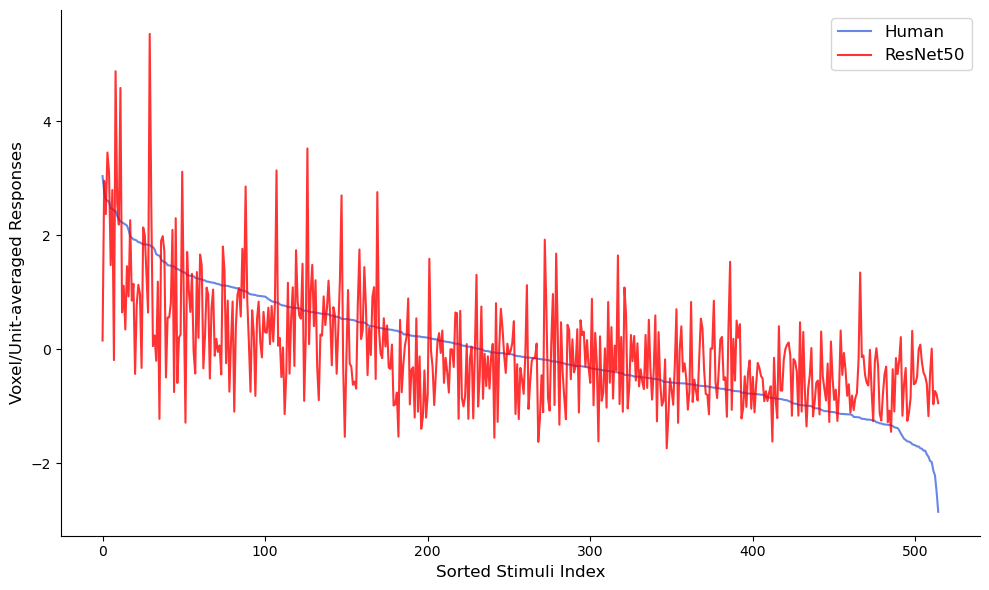

In [ ]:
# Subject sorted univariate responses
plt.figure(figsize=(10, 6))

# Sort the data according to subject_zscore for better visualization
sorted_indices = np.argsort(subject_zscore)[::-1]
sorted_subject_zscore = subject_zscore[sorted_indices]
sorted_model_zscore = model_zscore[sorted_indices]

# Plot the data
plt.plot(sorted_subject_zscore, color='royalblue', label='Human', alpha=0.8)
plt.plot(sorted_model_zscore, color='red', label='ResNet50', alpha=0.8)

# Plot the data
# plt.plot(subject_zscore, color='royalblue', label='Human', alpha=0.8)
# plt.plot(model_zscore, color='red', label='ResNet50', alpha=0.8)

# Add labels and title
plt.xlabel('Sorted Stimuli Index', fontsize=12)
plt.ylabel('Voxel/Unit-averaged Responses', fontsize=12)
# plt.title(f'Subject {subject} vs ResNet50 Responses in {froi}', fontsize=14)

# Add legend
plt.legend(loc='upper right', fontsize=12)

# Remove top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Tight layout
plt.tight_layout()

# Save the plot
plt.savefig(f'{plot_dir}/model_human_responses.pdf', dpi=300, bbox_inches='tight')

# Show the plot
# plt.show()

Correlation between subject 2 and ResNet50 (FFA) responses: 0.561


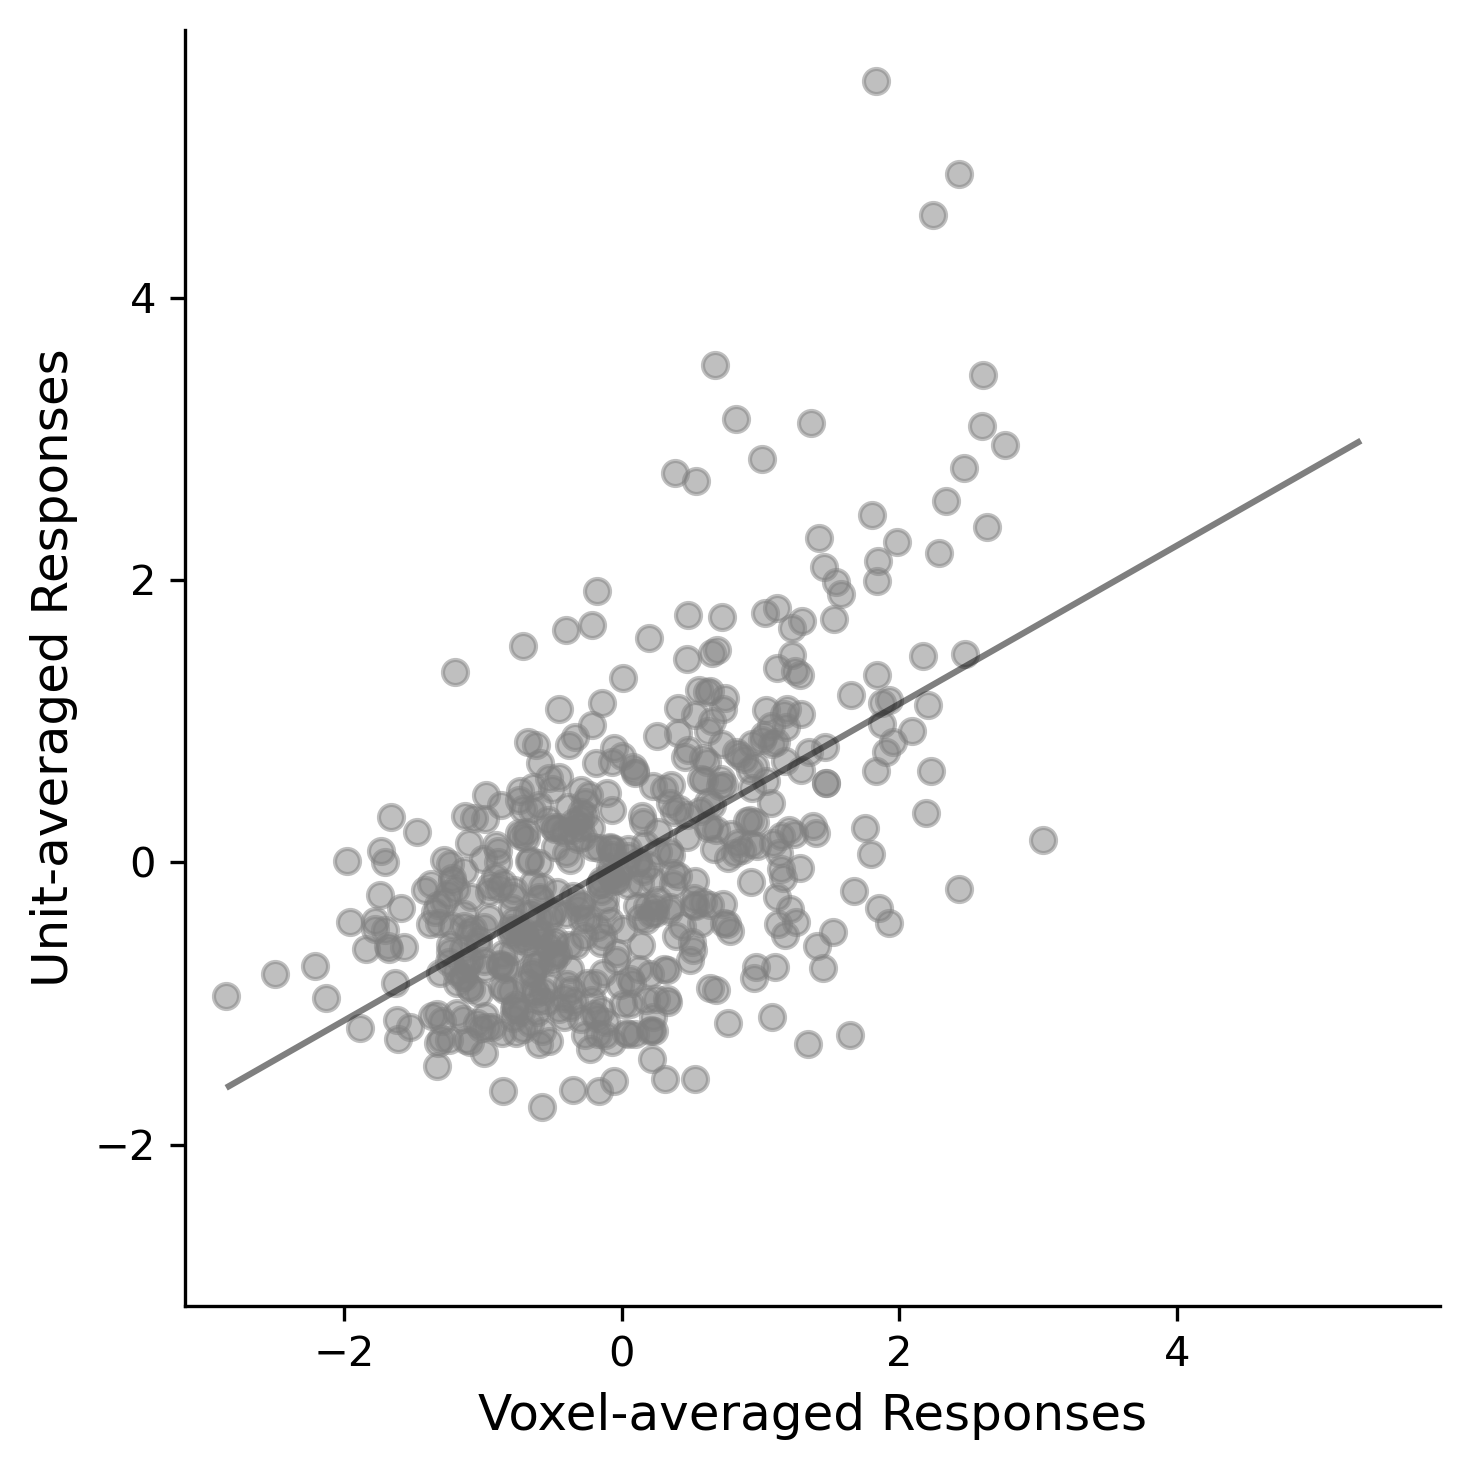

In [5]:
# Create scatter plot of z-scored responses
plt.figure(figsize=(5, 5), dpi=300)
plt.scatter(subject_zscore, model_zscore, alpha=0.5, c='gray')

# Calculate correlation (correlation doesn't change with z-scoring)
correlation = np.corrcoef(subject_data_np, model_data_np)[0, 1]
print(f'Correlation between subject {subject} and ResNet50 ({froi}) responses: {correlation:.3f}')

# Make the plot square by setting the same limits for both axes
xmin, xmax = plt.xlim()
ymin, ymax = plt.ylim()
plot_min = min(xmin, ymin)
plot_max = max(xmax, ymax)
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)

# Add regression line spanning almost the whole plot
m, b = np.polyfit(subject_zscore, model_zscore, 1)
x_range = np.linspace(plot_min * 0.9, plot_max * 0.9, 100)
plt.plot(x_range, m*x_range + b, color='k', alpha=0.5)

# Add labels and title
plt.xlabel('Voxel-averaged Responses', fontsize=12)
plt.ylabel('Unit-averaged Responses', fontsize=12)
# plt.title(f'Correlation between Subject {subject} and ResNet50 ({froi}) responses\nPearson r = {correlation:.3f}', fontsize=14)

# Remove top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add 1:1 diagonal line
# plt.plot([plot_min, plot_max], [plot_min, plot_max], 'k--', alpha=0.5, label='1:1 line')
# plt.legend()

# Add grid for better readability
# plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(f'{plot_dir}/model_human_correlation.pdf', dpi=300, bbox_inches='tight')
# plt.show()

Saving fROI models/resnet18imagenet1kv1/grillspector/FFA/layer4.1.relu1/resnet18imagenet1kv1_layer4.1.relu1_grillspector_FFA_2.00.pt
Correlation between subject 2 and ResNet50 (FFA) responses: 0.406


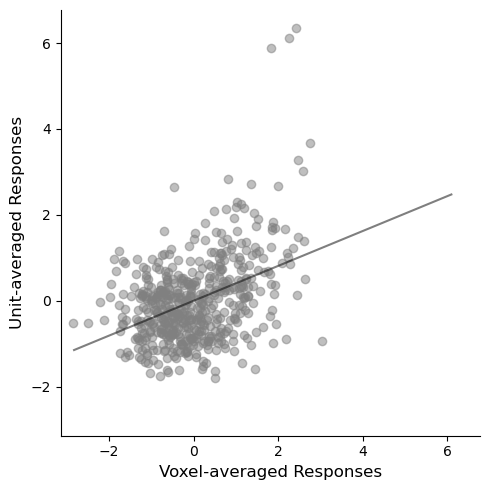

In [37]:
model = resnet18_imagenet1kv1.get_model()
# Load a subject's data
subject_data, _ = nsd.get_betas(
    NSD_DIR, subject, froi=froi, tthreshold=tthreshold, subset=subset, voxels=False
)
model_data = model_utils.get_dataset_activations(
    MODELS_DIR, NSD_DIR, model, ma.get_froi_models_layers(froi, froi)[model.name],
    dataset='nsd', subset=subset, froi=froi, tthreshold=tthreshold,
    froi_localizer=model_localizer, froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR, device='cpu'
).mean(axis=-1)

# Univariate responses for both model and subject
# Z-score both datasets separately
subject_data_np = subject_data.cpu().numpy()
model_data_np = model_data.cpu().numpy()

# Z-score
subject_zscore = (subject_data_np - np.mean(subject_data_np)) / np.std(subject_data_np)
model_zscore = (model_data_np - np.mean(model_data_np)) / np.std(model_data_np)

# Create scatter plot of z-scored responses
plt.figure(figsize=(5, 5))
plt.scatter(subject_zscore, model_zscore, alpha=0.5, c='gray')

# Calculate correlation (correlation doesn't change with z-scoring)
correlation = np.corrcoef(subject_data_np, model_data_np)[0, 1]
print(f'Correlation between subject {subject} and ResNet50 ({froi}) responses: {correlation:.3f}')

# Make the plot square by setting the same limits for both axes
xmin, xmax = plt.xlim()
ymin, ymax = plt.ylim()
plot_min = min(xmin, ymin)
plot_max = max(xmax, ymax)
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)

# Add regression line spanning almost the whole plot
m, b = np.polyfit(subject_zscore, model_zscore, 1)
x_range = np.linspace(plot_min * 0.9, plot_max * 0.9, 100)
plt.plot(x_range, m*x_range + b, color='k', alpha=0.5)

# Add labels and title
plt.xlabel('Voxel-averaged Responses', fontsize=12)
plt.ylabel('Unit-averaged Responses', fontsize=12)
# plt.title(f'Correlation between Subject {subject} and ResNet50 ({froi}) responses\nPearson r = {correlation:.3f}', fontsize=14)

# Remove top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add 1:1 diagonal line
# plt.plot([plot_min, plot_max], [plot_min, plot_max], 'k--', alpha=0.5, label='1:1 line')
# plt.legend()

# Add grid for better readability
# plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(f'{plot_dir}/r18_s2_correlation.pdf', dpi=300, bbox_inches='tight')
# plt.show()

Correlation between subject 2 and ResNet50 (FFA) responses: 0.681


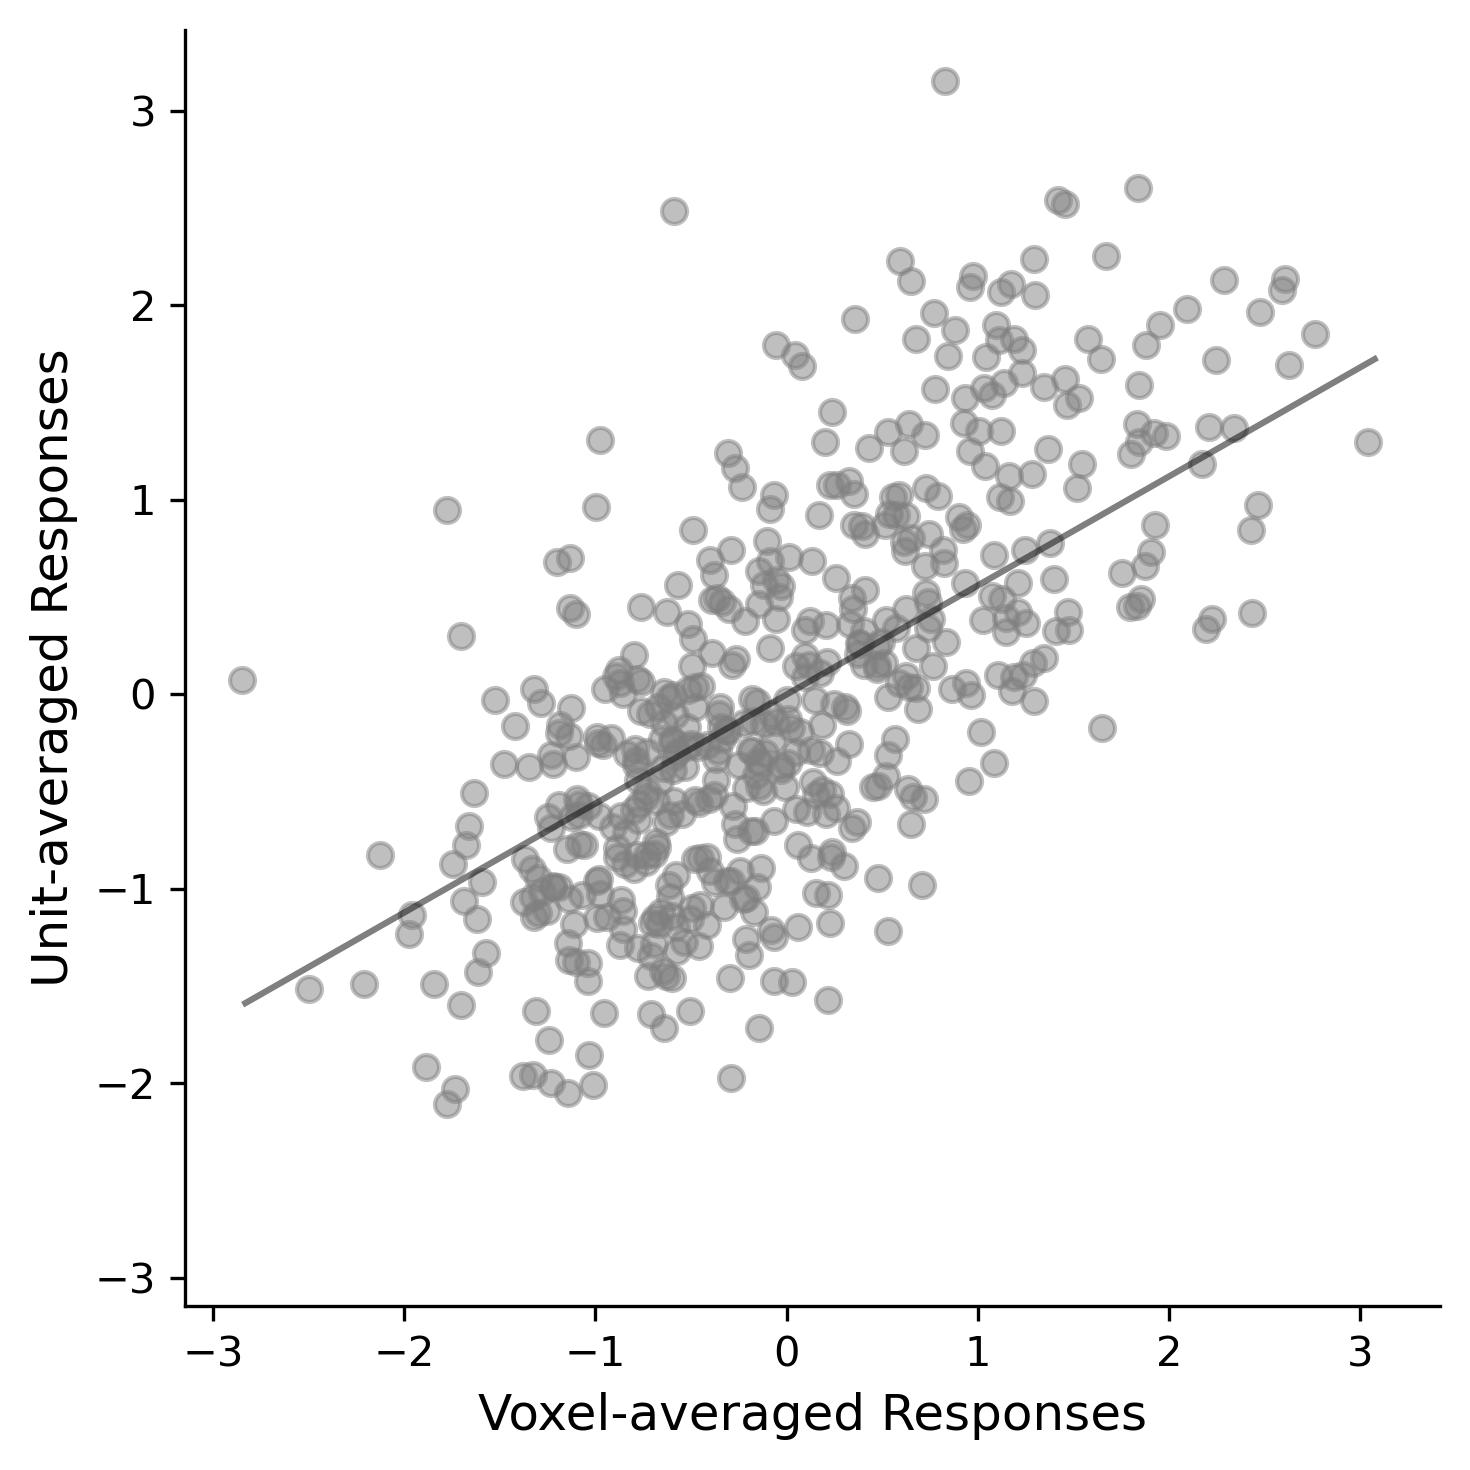

In [6]:
subject_data2, _ = nsd.get_betas(
    NSD_DIR, 5, froi=froi, tthreshold=tthreshold, subset=subset, voxels=False
)
subject_data2 = subject_data2.cpu().numpy()
subject_data2_zscore = (subject_data2 - np.mean(subject_data2)) / np.std(subject_data2)

# Create scatter plot of z-scored responses
plt.figure(figsize=(5, 5), dpi=300)
plt.scatter(subject_zscore, subject_data2_zscore, alpha=0.5, c='gray')

# Calculate correlation (correlation doesn't change with z-scoring)
correlation = np.corrcoef(subject_data_np, subject_data2_zscore)[0, 1]
print(f'Correlation between subject {subject} and ResNet50 ({froi}) responses: {correlation:.3f}')

# Make the plot square by setting the same limits for both axes
xmin, xmax = plt.xlim()
ymin, ymax = plt.ylim()
plot_min = min(xmin, ymin)
plot_max = max(xmax, ymax)
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)

# Add regression line spanning almost the whole plot
m, b = np.polyfit(subject_zscore, model_zscore, 1)
x_range = np.linspace(plot_min * 0.9, plot_max * 0.9, 100)
plt.plot(x_range, m*x_range + b, color='k', alpha=0.5)

# Add labels and title
plt.xlabel('Voxel-averaged Responses', fontsize=12)
plt.ylabel('Unit-averaged Responses', fontsize=12)
# plt.title(f'Correlation between Subject {subject} and ResNet50 ({froi}) responses\nPearson r = {correlation:.3f}', fontsize=14)

# Remove top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add 1:1 diagonal line
# plt.plot([plot_min, plot_max], [plot_min, plot_max], 'k--', alpha=0.5, label='1:1 line')
# plt.legend()

# Add grid for better readability
# plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(f'{plot_dir}/s5_s2_correlation.pdf', dpi=300, bbox_inches='tight')
# plt.show()

## Possibilities

In [30]:
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances
import numpy as np
import matplotlib.colors as mcolors


# Create two clusters of points with more separation
np.random.seed(42)

# Create synthetic data representing human and model clusters
# Increased separation between clusters (2 vs -2) and reduced variance (0.3)
human_points = np.random.randn(8, 10) * 0.1 + np.array([1.5, 0, 0, 0, 0, 0, 0, 0, 0, 0])
model_points = np.random.randn(30, 10) * 0.4 + np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

# Combine points for MDS
all_points = np.vstack([human_points, model_points])

# Compute distance matrix
distances = pairwise_distances(all_points)

# Apply MDS to get 2D coordinates
# Reduced eps to make the optimization more precise
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42, eps=1e-6)
mds_coords = mds.fit_transform(distances)

# Create colors and edge colors for the points
human_color = 'royalblue'
model_color = 'red'
# facecolors = [human_color] * 8 + [model_color] * 30
facecolors = [mcolors.to_rgba(human_color, alpha=0.75)] * 8 + [mcolors.to_rgba(model_color, alpha=0.75)] * 30
edgecolors = [human_color] * 8 + [model_color] * 30

plt.figure(figsize=(5, 5), dpi=300)
plt.scatter(mds_coords[:, 0], mds_coords[:, 1], fc=facecolors, ec=edgecolors, s=150)

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xticks([])
plt.yticks([])
plt.axis('off')

# Make the figure background transparent
plt.gcf().patch.set_alpha(0.0)
plt.tight_layout()
plt.savefig(f'{plot_dir}/possibility1.png', dpi=300)
plt.close()


In [31]:
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances
import numpy as np
import matplotlib.colors as mcolors


# Create two clusters of points with more separation
np.random.seed(42)

# Create synthetic data representing human and model clusters
# Increased separation between clusters (2 vs -2) and reduced variance (0.3)
human_points = np.random.randn(8, 10) * 0.25 + np.array([0.25, 0, 0, 0, 0, 0, 0, 0, 0, 0])
model_points = np.random.randn(30, 10) * 0.3 + np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

# Combine points for MDS
all_points = np.vstack([human_points, model_points])

# Compute distance matrix
distances = pairwise_distances(all_points)

# Apply MDS to get 2D coordinates
# Reduced eps to make the optimization more precise
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42, eps=1e-6)
mds_coords = mds.fit_transform(distances)

# Create colors and edge colors for the points
human_color = 'royalblue'
model_color = 'red'
# facecolors = [human_color] * 8 + [model_color] * 30
facecolors = [mcolors.to_rgba(human_color, alpha=0.75)] * 8 + [mcolors.to_rgba(model_color, alpha=0.75)] * 30
edgecolors = [human_color] * 8 + [model_color] * 30

plt.figure(figsize=(5, 5), dpi=300)
plt.scatter(mds_coords[:, 0], mds_coords[:, 1], fc=facecolors, ec=edgecolors, s=150)

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xticks([])
plt.yticks([])
plt.axis('off')

# Make the figure background transparent
plt.gcf().patch.set_alpha(0.0)
plt.tight_layout()
plt.savefig(f'{plot_dir}/possibility2.png', dpi=300)
plt.close()


In [32]:
mcolors.to_rgba(human_color, alpha=0.75)

(0.2549019607843137, 0.4117647058823529, 0.8823529411764706, 0.75)

In [34]:
mcolors.to_rgba(model_color)

(1.0, 0.0, 0.0, 1.0)

In [35]:
mcolors.to_hex('royalblue')

'#4169e1'